## Análise 2: grau de risco x tipo de ação
Pergunta: a resposta da Defesa Civil muda conforme o grau de risco? A consulta cruza a fato com a **dim_tipo_acao** e a **dim_risco** e calcula, para cada categoria de ação, quanto dos atendimentos ocorreu em cada grau de risco (R1 a R4). Ficam de fora as linhas sem ação ou sem risco informados.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from sqlalchemy import create_engine

load_dotenv("../.env")
engine = create_engine(
    f"postgresql+psycopg2://{os.getenv('DB_USER')}:{os.getenv('DB_PASSWORD')}"
    f"@{os.getenv('DB_HOST')}:{os.getenv('DB_PORT')}/{os.getenv('DB_NAME')}"
)

### Consulta

In [2]:
# mesma consulta salva em analises/analise_2_risco_x_tipo_acao.sql
consulta = open("../analises/analise_2_risco_x_tipo_acao.sql", encoding="utf-8").read()
resultado = pd.read_sql(consulta, con=engine)
resultado

,categoria_acao,codigo_risco,descricao_risco,atendimentos,percentual_na_categoria
0,Assistência humanitária,R1,baixo,1,9.1
1,Assistência humanitária,R2,médio,2,18.2
2,Assistência humanitária,R3,alto,4,36.4
3,Assistência humanitária,R4,muito alto,4,36.4
4,Assistência social,R1,baixo,1621,5.0
5,Assistência social,R2,médio,6585,20.4
6,Assistência social,R3,alto,23461,72.7
7,Assistência social,R4,muito alto,624,1.9
8,Avaliação técnica de risco,R1,baixo,3989,14.4
9,Avaliação técnica de risco,R2,médio,7882,28.4


### Gráfico

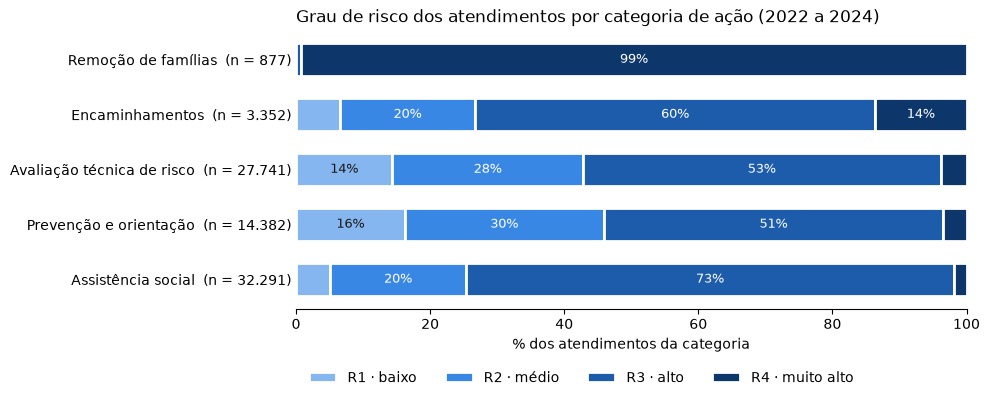

In [5]:
# resultado da consulta em formato de tabela: uma linha por categoria, uma coluna por grau de risco
tabela = resultado.pivot(index="categoria_acao", columns="codigo_risco", values="atendimentos").fillna(0)
tabela = tabela[["R1", "R2", "R3", "R4"]]
total = tabela.sum(axis=1)
percentual = tabela.div(total, axis=0) * 100

# só categorias com pelo menos 100 atendimentos com risco informado, ordenadas pela fatia de R4
percentual = percentual[total >= 100].sort_values("R4")
rotulos = [f"{cat}  (n = {int(total[cat]):,})".replace(",", ".") for cat in percentual.index]

CORES = {"R1": "#86b6ef", "R2": "#3987e5", "R3": "#1c5cab", "R4": "#0d366b"}  # um tom de azul, do claro (baixo) ao escuro (muito alto)
NOMES = {"R1": "R1 · baixo", "R2": "R2 · médio", "R3": "R3 · alto", "R4": "R4 · muito alto"}

fig, ax = plt.subplots(figsize=(10, 4.2))
inicio = [0] * len(percentual)
for codigo in ["R1", "R2", "R3", "R4"]:
    valores = percentual[codigo].values
    barras = ax.barh(rotulos, valores, left=inicio, color=CORES[codigo], label=NOMES[codigo],
                     height=0.6, edgecolor="white", linewidth=2)
    # escreve o percentual só nos pedaços grandes o bastante
    for barra, valor in zip(barras, valores):
        if valor >= 8:
            ax.text(barra.get_x() + barra.get_width() / 2, barra.get_y() + barra.get_height() / 2,
                    f"{valor:.0f}%", ha="center", va="center", fontsize=9,
                    color="#1a1a19" if codigo == "R1" else "white")
    inicio = [a + b for a, b in zip(inicio, valores)]

ax.set_xlim(0, 100)
ax.set_xlabel("% dos atendimentos da categoria")
ax.set_title("Grau de risco dos atendimentos por categoria de ação (2022 a 2024)", loc="left", fontsize=12)
ax.legend(ncol=4, loc="upper left", bbox_to_anchor=(0, -0.18), frameon=False)
for lado in ["top", "right", "left"]:
    ax.spines[lado].set_visible(False)
ax.tick_params(axis="y", length=0)
plt.tight_layout()
plt.savefig("analise_2_risco_x_tipo_acao.png", dpi=150, bbox_inches="tight")
plt.show()


### Quando aconteceram as remoções de famílias

In [4]:
consulta = open("../analises/analise_2_remocoes_por_mes.sql", encoding="utf-8").read()
remocoes = pd.read_sql(consulta, con=engine)
remocoes

,ano,mes,nome_mes,remocoes
0,2022,5,maio,66
1,2022,6,junho,373
2,2022,7,julho,349
3,2022,8,agosto,92
4,2022,9,setembro,4
5,2023,2,fevereiro,71
6,2023,4,abril,1
7,2023,5,maio,4
8,2023,6,junho,2
9,2023,7,julho,4


### Insight
A resposta da Defesa Civil acompanha a gravidade do risco. A remoção de famílias é praticamente exclusiva das áreas R4: 99,2% das remoções com risco informado ocorreram em áreas de risco muito alto. Nas demais categorias com mais de 100 atendimentos, o R4 fica entre 1,9% e 13,6%. As remoções também se concentram no tempo: 884 das 990 aconteceram em 2022, quase todas entre maio e agosto, período das chuvas intensas no Recife, e caíram para 82 em 2023 e 24 em 2024. Uma limitação da base é que 54% dos atendimentos não têm grau de risco registrado.